# 02 - Hypothesis Testing
**Fair Mortgage Approval Decisions - ADS End-Term Project, Group 8**  |  BADIR stage: *Insights*

Every hypothesis from the pre-submission is tested at the **5% significance level** and classified as **Supported / Not supported / Inconclusive**, using a rule that is written down *before* looking at the result.

**Two things to keep in mind**
1. **Huge sample (1.3M rows):** nearly any difference becomes 'statistically significant'. So we always report the **size of the effect** and a **confidence interval**, not just a p-value.
2. **Association is not causation.** HMDA has no credit score and no repayment outcome. Only the regression discontinuity (H1) comes close to a causal design; the rest control for what we *can* observe.

| Hyp. | Claim | Methods used (all in the ADS handout) |
|---|---|---|
| H1 | Denials jump sharply above DTI 43% | Regression discontinuity (RDD) + placebo cutoffs |
| H2 | Race gap remains for similar applicants | Chi-square, logistic regression, propensity score matching |
| H3 | Low-income areas are denied more | Chi-square, logistic regression |
| H4 | Higher mortgage rates -> more denials, smaller loans | Correlation on yearly data, adjusted for applicant mix |
| H5, H6 | Gradient boosting AUC > 0.80; error gaps by group | Next notebook (`03_model_fairness`) |
| H7 | Non-banks differ from banks | Logistic regression + propensity score matching (lender type from the HMDA Reporter Panel) |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
ALPHA = 0.05
RNG = np.random.default_rng(42)

BLUE, ORANGE, INK, MUTED, GRID = "#2F5A45", "#8B2635", "#0b0b0b", "#52514e", "#e6e5e1"
from matplotlib import font_manager as _fm
for _p in Path.home().glob("AppData/Local/Microsoft/Windows/Fonts/Merriweather-*.ttf"):
    _fm.fontManager.addfont(str(_p))
plt.rcParams.update({"font.family": ["Merriweather", "DejaVu Serif", "serif"], "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True})

def finish(ax, title, subtitle=None, name=None):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=22 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
    plt.tight_layout()
    if name:
        plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

RESULTS = []   # one row per hypothesis, filled in as we go and shown in the final table
def record(hyp, method, estimate, ci, p, verdict, note):
    RESULTS.append(dict(hypothesis=hyp, method=method, estimate=estimate, ci_95=ci, p_value=p, verdict=verdict, note=note))

cols = ["denied", "year", "state_code", "derived_race", "derived_sex", "applicant_age", "loan_type", "dti_mid",
        "dti_is_exact", "loan_to_value_ratio", "income_w", "loan_amount_w", "loan_amount_real", "income_real",
        "tract_to_msa_income_percentage", "low_income_tract", "fred_mortgage_rate_30y", "lender_type"]
df = pd.read_parquet(ROOT / "data" / "processed" / "ssot.parquet", columns=cols)
df["state_code"] = df["state_code"].astype(str)
df["age"] = df["applicant_age"].astype(str).fillna("missing")
df["sex"] = df["derived_sex"].astype(str)
df["ltv"] = df["loan_to_value_ratio"]
df["loan_type"] = df["loan_type"].astype(str)
print(f"{len(df):,} rows loaded")

1,320,227 rows loaded


## H1 - Do denials go up sharply when DTI goes above 43%?
**Design: regression discontinuity (RDD).** Idea: applicants with DTI 43 and DTI 44 are almost identical, but 44 falls on the 'above 43%' side of the lender's rule of thumb. If the 43% rule really bites, the denial rate should *jump* between 43 and 44, over and above the normal upward trend.

* HMDA reports **exact** DTI only for 36-49, so we use those rows (about 636,000). Rows with ranges cannot be used because they hide the exact DTI.
* Model (a linear probability model) inside a small window around the cutoff: `denied = a + b*above + c*x + d*above*x`, where `x` = distance from the cutoff. **`b` is the jump.** Standard errors are clustered by state.
* **Placebo test:** run the same model at *fake* cutoffs (38-46). If the jump at 43 is not clearly bigger than at fake cutoffs, there is nothing special about 43.

**Decision rule (fixed in advance):** *Supported* if the jump at 43 is positive, statistically significant (p < 0.05) **and** larger than the jump at every placebo cutoff. Otherwise *Not supported*.

In [2]:
e = df[df["dti_is_exact"] & df["dti_mid"].between(36, 49)].copy()
e["dti_int"] = e["dti_mid"].round().astype(int)
e["state_id"] = e["state_code"].astype("category").cat.codes
print(f"Exact-DTI rows used: {len(e):,}")
print(e.groupby("dti_int").denied.agg(["mean", "size"]).round(4).T.to_string())

def rdd(data, cutoff, bw):
    """Jump in denial rate between DTI = cutoff and cutoff+1, using `bw` DTI points on each side."""
    s = data[(data.dti_int > cutoff - bw) & (data.dti_int <= cutoff + bw)].copy()
    s["above"] = (s.dti_int > cutoff).astype(int)
    s["x"] = s.dti_int - (cutoff + 0.5)
    m = smf.ols("denied ~ above + x + above:x", s).fit(cov_type="cluster", cov_kwds={"groups": s["state_id"]})
    b, se = m.params["above"], m.bse["above"]
    return b * 100, (b - 1.96 * se) * 100, (b + 1.96 * se) * 100, m.pvalues["above"], len(s)   # in percentage points

rows = []
for bw in [2, 3, 5, 7]:
    b, lo, hi, p, n = rdd(e, 43, bw)
    rows.append(dict(bandwidth=f"+/-{bw}", jump_pp=round(b, 2), ci_low=round(lo, 2), ci_high=round(hi, 2), p=round(p, 4), n=n))
print("\nJump at DTI 43 -> 44 (percentage points of denial rate), different window sizes:")
display(pd.DataFrame(rows))

Exact-DTI rows used: 636,043
dti_int         36          37         38          39         40          41          42          43         44          45          46          47          48          49
mean         0.073      0.0728      0.075      0.0766      0.077      0.0784      0.0757      0.0818      0.081      0.0901      0.0998      0.0986      0.1036      0.0914
size     40667.000  42393.0000  44572.000  46845.0000  48482.000  49421.0000  53011.0000  48860.0000  53953.000  41209.0000  38344.0000  38323.0000  40411.0000  49552.0000



Jump at DTI 43 -> 44 (percentage points of denial rate), different window sizes:


,bandwidth,jump_pp,ci_low,ci_high,p,n
0,+/-2,-0.85,-1.42,-0.27,0.0038,197033
1,+/-3,-0.50,-0.85,-0.14,0.0058,284798
2,+/-5,0.05,-0.25,0.35,0.7526,458859
3,+/-7,0.51,0.26,0.75,0.0001,595376


 cutoff   jump     lo     hi     p
     38  0.078 -0.356  0.513 0.724
     39  0.042 -0.278  0.361 0.797
     40 -0.167 -0.588  0.255 0.438
     41 -0.317 -0.673  0.039 0.081
     42  0.216 -0.213  0.644 0.324
     43 -0.496 -0.848 -0.144 0.006
     44  0.623  0.255  0.990 0.001
     45  0.783  0.303  1.263 0.001
     46 -0.081 -0.559  0.397 0.739


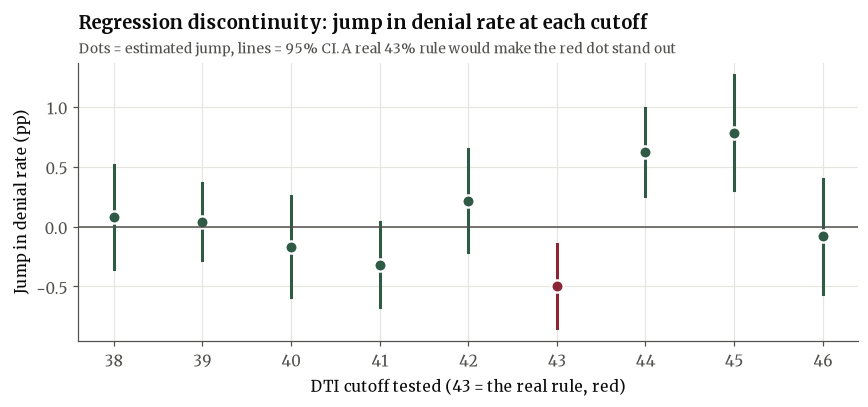


Jump at 43: -0.50 pp (95% CI -0.85 to -0.14, p = 0.0058);  largest placebo jump: 0.78 pp


In [3]:
# Placebo cutoffs (bandwidth 3 each side) - the real cutoff is 43
pl = []
for c in range(38, 47):
    b, lo, hi, p, n = rdd(e, c, 3)
    pl.append(dict(cutoff=c, jump=b, lo=lo, hi=hi, p=p))
pl = pd.DataFrame(pl)
print(pl.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
for _, r in pl.iterrows():
    col = ORANGE if r.cutoff == 43 else BLUE
    ax.plot([r.cutoff, r.cutoff], [r.lo, r.hi], color=col, lw=2)
    ax.plot(r.cutoff, r.jump, "o", color=col, ms=8, mec="white", mew=1.5)
ax.axhline(0, color=MUTED, lw=1); ax.set_xticks(pl.cutoff)
ax.set_xlabel("DTI cutoff tested (43 = the real rule, red)"); ax.set_ylabel("Jump in denial rate (pp)")
finish(ax, "Regression discontinuity: jump in denial rate at each cutoff", "Dots = estimated jump, lines = 95% CI. A real 43% rule would make the red dot stand out", "11_rdd_placebo")

real = pl[pl.cutoff == 43].iloc[0]
others_max = pl[pl.cutoff != 43].jump.abs().max()
supported = (real.jump > 0) and (real.p < ALPHA) and (real.jump > pl[pl.cutoff != 43].jump.max())
print(f"\nJump at 43: {real.jump:.2f} pp (95% CI {real.lo:.2f} to {real.hi:.2f}, p = {real.p:.4f});  largest placebo jump: {pl[pl.cutoff != 43].jump.max():.2f} pp")
record("H1", "RDD at DTI 43 (bw +/-3) + placebo cutoffs", f"{real.jump:.2f} pp", f"{real.lo:.2f} to {real.hi:.2f}", real.p,
       "Supported" if supported else "Not supported",
       "Denials rise gradually with DTI; compare jump at 43 with placebo cutoffs. Large jumps exist only at 50%+ (outside RDD range).")

In [4]:
# Plain chi-square for completeness: all rows with an exact DTI, 'DTI <= 43' vs 'DTI > 43'
tab = pd.crosstab(e.dti_mid > 43, e.denied)
chi2, p, _, _ = stats.chi2_contingency(tab)
r_low, r_high = e[e.dti_mid <= 43].denied.mean(), e[e.dti_mid > 43].denied.mean()
print(f"Denial rate DTI 36-43: {r_low:.2%}   DTI 44-49: {r_high:.2%}   difference {100*(r_high-r_low):.2f} pp   chi2 p = {p:.2e}")
print("-> Statistically significant (huge n) but the RDD shows this is the continuing slope, not a break at 43.")

Denial rate DTI 36-43: 7.64%   DTI 44-49: 9.32%   difference 1.68 pp   chi2 p = 1.14e-125
-> Statistically significant (huge n) but the RDD shows this is the continuing slope, not a break at 43.


### H1 - extra check (not part of the pre-set rule): does a jump at 43% show up for specific loan types?
FHA and VA loans have different DTI guidelines from conventional loans, so a rule at 43% could hide inside one loan type. Same RDD, run separately by loan type. **This does not change the H1 verdict**; it tells us whether the 'Not supported' result is hiding a sub-group effect.

In [5]:
names = {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA / RHS"}
rows = []
for lt, name in names.items():
    sub = e[e.loan_type == lt]
    if len(sub) < 20000:
        continue
    b, lo, hi, p, n = rdd(sub, 43, 3)
    rows.append(dict(loan_type=name, rows_in_window=n, jump_pp=round(b, 2), ci_low=round(lo, 2), ci_high=round(hi, 2), p=round(p, 4)))
h1_by_type = pd.DataFrame(rows); display(h1_by_type)
print("A jump at 43 is only convincing if it is positive, significant AND clearly bigger than the placebo jumps seen earlier (up to ~0.8 pp).")

,loan_type,rows_in_window,jump_pp,ci_low,ci_high,p
0,Conventional,193666,-0.63,-1.14,-0.13,0.0132
1,FHA,59023,-0.15,-1.21,0.91,0.7824
2,VA,27005,-0.73,-1.81,0.35,0.1846


A jump at 43 is only convincing if it is positive, significant AND clearly bigger than the placebo jumps seen earlier (up to ~0.8 pp).


## Preparing the data for H2, H3 and H4
For regressions and matching we need complete information on the control variables. We keep **complete cases** (rows with DTI, LTV, income and loan amount) and report how many rows that drops.

**Controls ('similar applicants'):** DTI, LTV, income, loan amount, loan type, applicant age, sex, year; and in the extended model also state and the neighbourhood's income level.

**Known limit:** HMDA has **no credit score**, which strongly drives real lending decisions. Any remaining gap could partly reflect credit differences we cannot see.

In [6]:
need = ["dti_mid", "ltv", "income_w", "loan_amount_w", "tract_to_msa_income_percentage"]
m = df.dropna(subset=need).copy()
m = m[m.tract_to_msa_income_percentage > 0]              # 0 = tract income not available
print(f"Complete cases: {len(m):,} of {len(df):,} rows ({len(m)/len(df):.1%}); dropped {len(df)-len(m):,}")
print("Denial rate in dropped rows:", f"{df.loc[~df.index.isin(m.index),'denied'].mean():.1%}", "vs kept rows:", f"{m.denied.mean():.1%}")
m["black"] = (m.derived_race == "Black or African American").astype(int)
m["white"] = (m.derived_race == "White").astype(int)
m["low_tract"] = (m.tract_to_msa_income_percentage < 80).astype(int)

# A 400k random sample keeps the logistic regressions fast; the matching below uses all rows.
S = m.sample(400_000, random_state=42).copy()
S["state_id"] = S["state_code"].astype("category").cat.codes
print("Regression sample:", f"{len(S):,}")

FIN = "dti_mid + ltv + np.log(income_w) + np.log(loan_amount_w) + C(loan_type) + C(age) + C(sex) + C(year)"
def fit_logit(formula, data):
    return smf.logit(formula, data).fit(disp=0, cov_type="cluster", cov_kwds={"groups": data["state_id"]})

def odds_ratio(model, var):
    b, se = model.params[var], model.bse[var]
    return np.exp(b), np.exp(b - 1.96 * se), np.exp(b + 1.96 * se), model.pvalues[var]

def adj_gap(model, data, var):
    """Average adjusted difference in denial probability if everyone had var=1 vs var=0 (percentage points)."""
    d1, d0 = data.copy(), data.copy(); d1[var], d0[var] = 1, 0
    return 100 * (model.predict(d1).mean() - model.predict(d0).mean())

Complete cases: 1,170,521 of 1,320,227 rows (88.7%); dropped 149,706
Denial rate in dropped rows: 44.2% vs kept rows: 9.0%


Regression sample: 400,000


## H2 - Is there a denial gap by race for applicants with similar income, loan size and DTI?
We compare **Black** and **White** applicants (the two largest groups; Joint and 'not available' are left out of this test).

Three lines of evidence, from simplest to strongest:
1. **Chi-square test** on the raw gap.
2. **Logistic regression** with controls. An **odds ratio (OR) > 1** means higher odds of denial than comparable White applicants.
3. **Propensity score matching (PSM):** pair each Black applicant with a White applicant who had a very similar *probability of being Black given their financial profile and location*, then compare outcomes within pairs.

**Decision rule:** *Supported* if the adjusted gap is positive with a 95% CI above zero in **both** the regression (OR CI above 1) **and** the matched comparison. *Not supported* if neither shows a gap. *Inconclusive* if they disagree.

In [7]:
# 1. Raw gap + chi-square
rw = m[(m.black == 1) | (m.white == 1)]
tab = pd.crosstab(rw.black, rw.denied)
chi2, p_chi, _, _ = stats.chi2_contingency(tab)
rb, rwh = rw[rw.black == 1].denied.mean(), rw[rw.white == 1].denied.mean()
print(f"Raw denial rate: Black {rb:.1%} (n={int(rw.black.sum()):,}), White {rwh:.1%} (n={int(rw.white.sum()):,}); gap {100*(rb-rwh):.1f} pp; chi-square p = {p_chi:.1e}")

Raw denial rate: Black 16.1% (n=94,413), White 7.7% (n=810,323); gap 8.3 pp; chi-square p = 0.0e+00


In [8]:
# 2. Logistic regression with controls (Black vs White, regression sample)
Sr = S[(S.black == 1) | (S.white == 1)].copy()
mA = fit_logit("denied ~ black + " + FIN, Sr)                                              # financial controls only
mB = fit_logit("denied ~ black + " + FIN + " + tract_to_msa_income_percentage + C(state_code)", Sr)  # + place
out = []
for name, mod in [("A: financial controls", mA), ("B: + neighbourhood income + state", mB)]:
    orr, lo, hi, p = odds_ratio(mod, "black")
    out.append(dict(model=name, odds_ratio=round(orr, 2), ci_low=round(lo, 2), ci_high=round(hi, 2), p=p,
                    adjusted_gap_pp=round(adj_gap(mod, Sr, "black"), 2)))
lg = pd.DataFrame(out); display(lg)

,model,odds_ratio,ci_low,ci_high,p,adjusted_gap_pp
0,A: financial controls,1.73,1.63,1.84,9.201252e-73,4.65
1,B: + neighbourhood income + state,1.73,1.65,1.82,2.076442e-106,4.62


In [9]:
# 3. Propensity score matching (all complete White + Black rows)
P = m[(m.black == 1) | (m.white == 1)].copy()
num = ["dti_mid", "ltv", "income_w", "loan_amount_w", "tract_to_msa_income_percentage"]
Xn = P[num].copy(); Xn[["income_w", "loan_amount_w"]] = np.log(Xn[["income_w", "loan_amount_w"]])
Xn = (Xn - Xn.mean()) / Xn.std()                                          # standardise numeric covariates
Xc = pd.get_dummies(P[["loan_type", "age", "sex", "year", "state_code"]].astype(str), drop_first=True).astype("float32")
X = pd.concat([Xn.astype("float32"), Xc], axis=1)
ps_model = LogisticRegression(max_iter=300).fit(X, P.black)
ps = np.clip(ps_model.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
lps = np.log(ps / (1 - ps))                                               # logit of the propensity score
P["lps"] = lps

treated, control = P[P.black == 1], P[P.black == 0]
nn = NearestNeighbors(n_neighbors=1).fit(control[["lps"]].values)
dist, idx = nn.kneighbors(treated[["lps"]].values)
caliper = 0.2 * lps.std()                                                 # standard rule of thumb
ok = dist[:, 0] <= caliper
t_y = treated.denied.values[ok]; c_y = control.denied.values[idx[ok, 0]]
att = (t_y - c_y).mean() * 100
boot = [(lambda i: (t_y[i] - c_y[i]).mean() * 100)(RNG.integers(0, len(t_y), len(t_y))) for _ in range(500)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Matched {ok.sum():,} of {len(treated):,} Black applicants (caliper {caliper:.3f}; controls reused: {len(set(idx[ok,0])):,} distinct White applicants)")
print(f"Denial rate: Black {t_y.mean():.1%} vs matched White {c_y.mean():.1%}  ->  gap (ATT) = {att:.2f} pp, 95% bootstrap CI [{lo:.2f}, {hi:.2f}]")

Matched 94,413 of 94,413 Black applicants (caliper 0.281; controls reused: 74,585 distinct White applicants)
Denial rate: Black 16.1% vs matched White 11.4%  ->  gap (ATT) = 4.71 pp, 95% bootstrap CI [4.39, 5.01]


,before,after
variable,,
dti_mid,0.444,-0.007
ltv,0.601,0.004
income_w,-0.259,0.002
loan_amount_w,-0.126,0.024
tract_to_msa_income_percentage,-0.371,-0.001


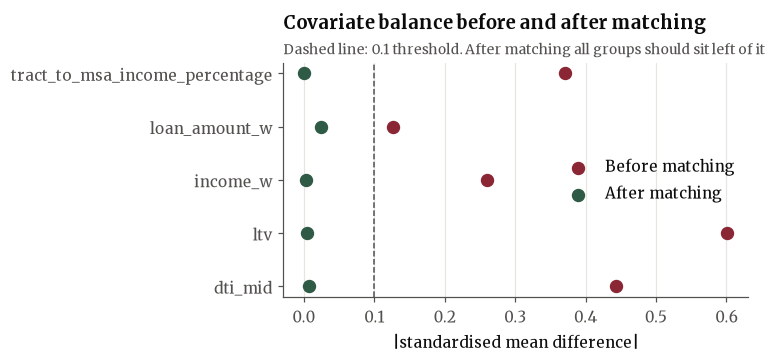

In [10]:
# Balance check: did matching make the two groups look alike? (standardised mean difference, |SMD| < 0.1 is good)
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
raw_t, raw_c = treated, control
mt, mc = treated.iloc[np.where(ok)[0]], control.iloc[idx[ok, 0]]
bal = []
for c in ["dti_mid", "ltv", "income_w", "loan_amount_w", "tract_to_msa_income_percentage"]:
    bal.append(dict(variable=c, before=smd(raw_t[c], raw_c[c]), after=smd(mt[c], mc[c])))
bal = pd.DataFrame(bal).set_index("variable"); display(bal.round(3))

fig, ax = plt.subplots(figsize=(7, 3.4)); y = np.arange(len(bal))
ax.scatter(bal.before.abs(), y, color=ORANGE, s=60, label="Before matching", zorder=3)
ax.scatter(bal.after.abs(), y, color=BLUE, s=60, label="After matching", zorder=3)
ax.axvline(0.1, color=MUTED, ls="--", lw=1); ax.set_yticks(y); ax.set_yticklabels(bal.index)
ax.set_xlabel("|standardised mean difference|"); ax.legend(frameon=False); ax.grid(axis="y", visible=False)
finish(ax, "Covariate balance before and after matching", "Dashed line: 0.1 threshold. After matching all groups should sit left of it", "12_psm_balance")

In [11]:
orA = lg.iloc[0]; orB = lg.iloc[1]
reg_supports = (orA.ci_low > 1) and (orB.ci_low > 1)
psm_supports = lo > 0
if reg_supports and psm_supports:
    verdict = "Supported"
elif (not reg_supports) and (not psm_supports):
    verdict = "Not supported"
else:
    verdict = "Inconclusive"
print("Regression says gap:", reg_supports, "| matching says gap:", psm_supports, "->", verdict)
record("H2", "Logit (OR) + PSM ATT, Black vs White", f"OR {orB.odds_ratio} (model B); PSM gap {att:.2f} pp",
       f"OR {orB.ci_low}-{orB.ci_high}; PSM [{lo:.2f}, {hi:.2f}] pp", p_chi, verdict,
       "Association after controlling for observables; no credit score in HMDA, so not proof of discrimination.")

Regression says gap: True | matching says gap: True -> Supported


## H3 - Do people from low-income areas get denied more than similar people elsewhere?
'Low-income area' = the tract's median family income is below 80% of its metro area (FFIEC 'low' and 'moderate' tracts). We compare with applicants in middle/upper-income tracts, then repeat with controls for the applicant's own income, loan, DTI, LTV, and **state** (so we compare within the same state).

**Decision rule:** *Supported* if the adjusted odds ratio's 95% CI is above 1. *Not supported* if the CI is below 1 or includes 1 with a gap under 1 percentage point. Otherwise *Inconclusive*.

In [12]:
tab = pd.crosstab(m.low_tract, m.denied); chi2, p3, _, _ = stats.chi2_contingency(tab)
r1, r0 = m[m.low_tract == 1].denied.mean(), m[m.low_tract == 0].denied.mean()
print(f"Raw denial rate: low/moderate tracts {r1:.1%} (n={int(m.low_tract.sum()):,}) vs other tracts {r0:.1%}; gap {100*(r1-r0):.1f} pp; chi-square p = {p3:.1e}")

m3 = fit_logit("denied ~ low_tract + " + FIN + " + C(state_code)", S.assign(low_tract=(S.tract_to_msa_income_percentage < 80).astype(int)))
orr, lo3, hi3, p = odds_ratio(m3, "low_tract")
gap3 = adj_gap(m3, S.assign(low_tract=(S.tract_to_msa_income_percentage < 80).astype(int)), "low_tract")
print(f"Adjusted odds ratio: {orr:.2f} (95% CI {lo3:.2f}-{hi3:.2f}), p = {p:.1e}; adjusted gap = {gap3:.2f} pp")
verdict3 = "Supported" if lo3 > 1 else ("Not supported" if (hi3 < 1 or abs(gap3) < 1) else "Inconclusive")
record("H3", "Chi-square + logit with controls (low/moderate tract)", f"OR {orr:.2f}; adj. gap {gap3:.2f} pp", f"{lo3:.2f} to {hi3:.2f}", p, verdict3,
       "Compared within the same state, controlling for applicant income, loan, DTI, LTV. Neighbourhood effect, not proof of cause.")

Raw denial rate: low/moderate tracts 12.0% (n=209,663) vs other tracts 8.4%; gap 3.6 pp; chi-square p = 0.0e+00


Adjusted odds ratio: 1.17 (95% CI 1.11-1.22), p = 3.5e-10; adjusted gap = 1.21 pp


## Robustness: what about the rows with missing data?
H2 and H3 above use complete cases, but the dropped rows had a **44% denial rate** (denied applications often lack DTI, LTV or income). To check that this does not change the conclusions, we repeat both models on **all** rows: missing values are filled with the median and a **missing-value flag** is added for each of DTI, LTV and income, so the model can use 'missingness' itself.

In [13]:
a = df[df.tract_to_msa_income_percentage.notna() & (df.tract_to_msa_income_percentage > 0)].copy()
for c, flag in [("dti_mid", "dti_miss"), ("ltv", "ltv_miss"), ("income_w", "inc_miss")]:
    a[flag] = a[c].isna().astype(int)
    a[c] = a[c].fillna(a[c].median())
a["black"] = (a.derived_race == "Black or African American").astype(int)
a["white"] = (a.derived_race == "White").astype(int)
a["low_tract"] = (a.tract_to_msa_income_percentage < 80).astype(int)
SA = a.sample(400_000, random_state=42).copy(); SA["state_id"] = SA["state_code"].astype("category").cat.codes
FLAGS = " + dti_miss + ltv_miss + inc_miss"
print(f"All rows used: {len(a):,} (vs {len(m):,} complete cases); denial rate {a.denied.mean():.1%}")

SAr = SA[(SA.black == 1) | (SA.white == 1)]
mr2 = fit_logit("denied ~ black + " + FIN + FLAGS + " + tract_to_msa_income_percentage + C(state_code)", SAr)
o2, l2, h2_, p2 = odds_ratio(mr2, "black")
mr3 = fit_logit("denied ~ low_tract + " + FIN + FLAGS + " + C(state_code)", SA)
o3, l3, h3_, p3_ = odds_ratio(mr3, "low_tract")
print(f"H2 (Black vs White), ALL rows with missing flags: OR {o2:.2f} (95% CI {l2:.2f}-{h2_:.2f}); adjusted gap {adj_gap(mr2, SAr, 'black'):.2f} pp   [complete cases: OR {orB.odds_ratio}]")
print(f"H3 (low/moderate tract), ALL rows with missing flags: OR {o3:.2f} (95% CI {l3:.2f}-{h3_:.2f}); adjusted gap {adj_gap(mr3, SA, 'low_tract'):.2f} pp   [complete cases: OR {orr:.2f}]")
ROBUST = dict(h2=(o2, l2, h2_), h3=(o3, l3, h3_))

All rows used: 1,299,817 (vs 1,170,521 complete cases); denial rate 12.0%


H2 (Black vs White), ALL rows with missing flags: OR 1.76 (95% CI 1.66-1.87); adjusted gap 5.47 pp   [complete cases: OR 1.73]


H3 (low/moderate tract), ALL rows with missing flags: OR 1.14 (95% CI 1.09-1.19); adjusted gap 1.16 pp   [complete cases: OR 1.17]


## H4 - When mortgage rates are high, are more loans denied and are loan amounts smaller?
The FRED mortgage rate is **one national number per year**, so we only have **6 data points (2018-2023)**. To avoid mixing in changes in *who applies*, we first compute each year's **adjusted** denial rate (same logistic model with year effects, averaged over all applicants) and then correlate it with the yearly rate.

**Decision rule:** with only 6 independent points, a correlation cannot separate the rate from everything else that changed (COVID, the 2021 refinance boom, house prices). We therefore classify as **Inconclusive** unless the evidence is very strong in *both* parts, in which case *Supported*.

,adj_denial_pct,raw_denial_pct,mortgage_rate,median_loan_real
2018,8.87,9.61,4.54,273031.91
2019,8.08,8.69,3.94,280087.94
2020,8.80,8.59,3.11,300164.34
2021,9.01,8.15,2.96,320475.55
2022,9.67,9.46,5.34,327999.93
2023,9.95,10.23,6.81,315000.00


Rate vs adjusted denial rate: r = 0.73, p = 0.099   |   Rate vs median real loan amount: r = 0.23, p = 0.663   (n = 6 years)


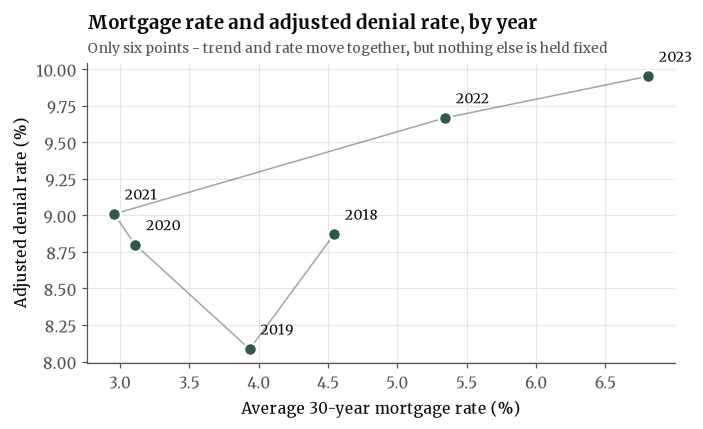

In [14]:
# adjusted denial rate per year, same applicants, only the year changes
mY = fit_logit("denied ~ " + FIN + " + tract_to_msa_income_percentage + C(state_code)", S)
adj = {}
for y in sorted(S.year.unique()):
    d = S.copy(); d["year"] = y
    adj[y] = 100 * mY.predict(d).mean()
yr = pd.DataFrame({"adj_denial_pct": pd.Series(adj)})
yr["raw_denial_pct"] = m.groupby("year").denied.mean() * 100
yr["mortgage_rate"] = m.groupby("year").fred_mortgage_rate_30y.first()
yr["median_loan_real"] = m.groupby("year").loan_amount_real.median()
display(yr.round(2))

r_den, p_den = stats.pearsonr(yr.mortgage_rate, yr.adj_denial_pct)
r_loan, p_loan = stats.pearsonr(yr.mortgage_rate, yr.median_loan_real)
print(f"Rate vs adjusted denial rate: r = {r_den:.2f}, p = {p_den:.3f}   |   Rate vs median real loan amount: r = {r_loan:.2f}, p = {p_loan:.3f}   (n = {len(yr)} years)")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(yr.mortgage_rate, yr.adj_denial_pct, color=BLUE, lw=1, alpha=0.5)
ax.scatter(yr.mortgage_rate, yr.adj_denial_pct, color=BLUE, s=70, zorder=3, edgecolor="white", linewidth=1.5)
for y, r in yr.iterrows():
    ax.text(r.mortgage_rate + 0.08, r.adj_denial_pct + 0.1, str(y), fontsize=9)
ax.set_xlabel("Average 30-year mortgage rate (%)"); ax.set_ylabel("Adjusted denial rate (%)")
finish(ax, "Mortgage rate and adjusted denial rate, by year", "Only six points - trend and rate move together, but nothing else is held fixed", "13_h4_rate_vs_denial")

strong = (p_den < 0.01) and (p_loan < 0.01) and (r_den > 0) and (r_loan < 0)
record("H4", "Pearson correlation on 6 yearly points (adjusted denial; median loan)", f"r={r_den:.2f} (denial), r={r_loan:.2f} (loan)",
       "n/a (6 points)", p_den, "Supported" if strong else "Inconclusive",
       "Only 6 time points and one national rate; cannot separate rates from COVID/boom effects. Direction is reported honestly.")

## H7 - Do non-bank lenders deny at a different rate than banks, for similar applicants?
Lender type comes from the **HMDA Reporter Panel** (joined on lender ID + year, 99.8% matched). Groups:
* **Non-bank:** independent mortgage companies (`other_lender_code = 3`).
* **Bank:** depository institutions that are not credit unions (`other_lender_code = 0`). Credit unions and bank affiliates are left out of this comparison (credit unions are shown for reference only).

Same two-step design as H2: a logistic regression with controls (including loan type, since FHA/VA loans are more common at non-banks, plus state and neighbourhood income) and propensity score matching on applicant characteristics. **The hypothesis is two-sided: 'different', not 'higher'.**

**Decision rule:** *Supported* if the regression odds-ratio CI excludes 1 **and** the matched-gap CI excludes 0. *Not supported* if both include the no-difference value. *Inconclusive* if they disagree.

In [15]:
print(m.groupby("lender_type").agg(rows=("denied", "size"), denial_rate=("denied", "mean")).assign(denial_rate=lambda t: (t.denial_rate * 100).round(1)).to_string())

L = m[m.lender_type.isin(["non_bank_mortgage_company", "bank"])].copy()
L["nonbank"] = (L.lender_type == "non_bank_mortgage_company").astype(int)
tab = pd.crosstab(L.nonbank, L.denied); chi2, p_l, _, _ = stats.chi2_contingency(tab)
rn, rb_ = L[L.nonbank == 1].denied.mean(), L[L.nonbank == 0].denied.mean()
print(f"Raw denial rate: non-bank {rn:.1%} (n={int(L.nonbank.sum()):,}) vs bank {rb_:.1%} (n={int((1-L.nonbank).sum()):,}); chi-square p = {p_l:.1e}")

SL = S.merge(L[["nonbank"]], left_index=True, right_index=True, how="inner")      # regression sample, same 400k draw
mL = fit_logit("denied ~ nonbank + " + FIN + " + tract_to_msa_income_percentage + C(state_code)", SL)
oL, loL, hiL, pL = odds_ratio(mL, "nonbank")
gapL = adj_gap(mL, SL, "nonbank")
print(f"Adjusted odds ratio (non-bank vs bank): {oL:.2f} (95% CI {loL:.2f}-{hiL:.2f}); adjusted gap {gapL:.2f} pp  [{len(SL):,} rows]")

                             rows  denial_rate
lender_type                                   
bank                       307651         10.2
bank_affiliate              58816          7.8
credit_union                72572         12.9
non_bank_mortgage_company  700699          8.1
unknown                     30783         12.2


Raw denial rate: non-bank 8.1% (n=700,699) vs bank 10.2% (n=307,651); chi-square p = 1.4e-268


Adjusted odds ratio (non-bank vs bank): 0.56 (95% CI 0.52-0.61); adjusted gap -4.60 pp  [344,891 rows]


In [16]:
# Propensity score matching: treated = non-bank applications, controls = bank applications
numL = ["dti_mid", "ltv", "income_w", "loan_amount_w", "tract_to_msa_income_percentage"]
Xn = L[numL].copy(); Xn[["income_w", "loan_amount_w"]] = np.log(Xn[["income_w", "loan_amount_w"]])
Xn = ((Xn - Xn.mean()) / Xn.std()).astype("float32")
Xc = pd.get_dummies(L[["loan_type", "age", "sex", "year", "state_code"]].astype(str), drop_first=True).astype("float32")
XL = pd.concat([Xn, Xc], axis=1)
psL = np.clip(LogisticRegression(max_iter=300).fit(XL, L.nonbank).predict_proba(XL)[:, 1], 1e-6, 1 - 1e-6)
L["lps"] = np.log(psL / (1 - psL))
tL, cL = L[L.nonbank == 1], L[L.nonbank == 0]
distL, idxL = NearestNeighbors(n_neighbors=1).fit(cL[["lps"]].values).kneighbors(tL[["lps"]].values)
okL = distL[:, 0] <= 0.2 * L.lps.std()
ty = tL.denied.values[okL]; cy = cL.denied.values[idxL[okL, 0]]
attL = (ty - cy).mean() * 100
bootL = [(lambda i: (ty[i] - cy[i]).mean() * 100)(RNG.integers(0, len(ty), len(ty))) for _ in range(300)]
loA, hiA = np.percentile(bootL, [2.5, 97.5])
print(f"Matched {okL.sum():,} of {len(tL):,} non-bank applications. Denial rate: non-bank {ty.mean():.1%} vs matched bank {cy.mean():.1%} -> gap {attL:.2f} pp (95% bootstrap CI {loA:.2f} to {hiA:.2f})")

reg_diff = (loL > 1) or (hiL < 1)
psm_diff = (loA > 0) or (hiA < 0)
verdict7 = "Supported" if (reg_diff and psm_diff) else ("Not supported" if (not reg_diff and not psm_diff) else "Inconclusive")
print("Regression finds a difference:", reg_diff, "| matching finds a difference:", psm_diff, "->", verdict7)
record("H7", "Logit (OR) + PSM ATT, non-bank vs bank", f"OR {oL:.2f}; PSM gap {attL:.2f} pp", f"OR {loL:.2f}-{hiL:.2f}; PSM [{loA:.2f}, {hiA:.2f}] pp", pL, verdict7,
       "Lender type from HMDA Reporter Panel (other_lender_code). Association only; lenders also differ in unobserved credit quality and products.")

Matched 700,698 of 700,699 non-bank applications. Denial rate: non-bank 8.1% vs matched bank 13.3% -> gap -5.21 pp (95% bootstrap CI -5.30 to -5.11)
Regression finds a difference: True | matching finds a difference: True -> Supported


## H5 and H6 - status
**H5** (gradient boosting AUC > 0.80, DTI and LTV matter most) and **H6** (error-rate gaps by group above 5%) are tested in the next notebook, `03_model_fairness`; their results are merged into the table below.

In [17]:
record("H5", "Gradient boosting + SHAP", "pending", "pending", np.nan, "Pending", "Next notebook (03_model_fairness).")
record("H6", "Error-rate fairness check", "pending", "pending", np.nan, "Pending", "Next notebook (03_model_fairness).")

res = pd.DataFrame(RESULTS)
prev_path = ROOT / "reports" / "hypothesis_results.csv"
# keep H5/H6 results written by notebook 03 so re-running this notebook does not reset them
if prev_path.exists():
    prev = pd.read_csv(prev_path)
    keep = prev[prev.hypothesis.isin(["H5", "H6"]) & (prev.verdict != "Pending")]
    res = pd.concat([res[~res.hypothesis.isin(keep.hypothesis)], keep]).sort_values("hypothesis")
res.to_csv(prev_path, index=False)
display(res[["hypothesis", "method", "estimate", "ci_95", "verdict"]])

,hypothesis,method,estimate,ci_95,verdict
0,H1,RDD at DTI 43 (bw +/-3) + placebo cutoffs,-0.50 pp,-0.85 to -0.14,Not supported
1,H2,"Logit (OR) + PSM ATT, Black vs White",OR 1.73 (model B); PSM gap 4.71 pp,"OR 1.65-1.82; PSM [4.39, 5.01] pp",Supported
2,H3,Chi-square + logit with controls (low/moderate...,OR 1.17; adj. gap 1.21 pp,1.11 to 1.22,Supported
3,H4,Pearson correlation on 6 yearly points (adjust...,"r=0.73 (denial), r=0.23 (loan)",n/a (6 points),Inconclusive
4,H5,"LightGBM (train 2018-22, test 2023) + SHAP",AUC 0.825 (complete cases); top-3: preapproval...,0.821 to 0.830,Inconclusive
5,H6,"Group error rates (FPR/FNR/error) vs White, 95...","[('Asian', 'FNR', np.float64(14.5))]",see notebook,Supported
4,H7,"Logit (OR) + PSM ATT, non-bank vs bank",OR 0.56; PSM gap -5.21 pp,"OR 0.52-0.61; PSM [-5.30, -5.11] pp",Supported
